# Rolling out a trained rat

This notebook loads a trained flexor-extensor Rat NCAP checkpoint and rolls it out in its
environment with `composer.utils.rollout.rollout_from_policy`, the rollout function that the test
script (`train/test.py`) uses:

1. **Target velocities:** one rollout of the policy at each of the training target velocities,
   rendered side by side.
2. **A changing brainstem command:** a rollout whose brainstem command (the `target_vx`
   observation) follows a function of time, recording the rat's velocity to plot it against the
   command.

It simulates with native MuJoCo physics on the CPU and runs the model on a GPU if there is one.
Rendering uses MuJoCo's OpenGL backend: `MUJOCO_GL=egl` on a GPU machine, or `MUJOCO_GL=osmesa`
without one. It expects the conda environment set up as in the repository's README.

In [1]:
import os

# MuJoCo's rendering backend: 'egl' on a GPU machine, 'osmesa' on a machine without a GPU.
MUJOCO_GL = 'osmesa'
os.environ['MUJOCO_GL'] = MUJOCO_GL
os.environ['PYOPENGL_PLATFORM'] = MUJOCO_GL

import hydra
import jax.numpy as jnp
import matplotlib.pyplot as plt
import mediapy
import numpy as np
import torch

import composer as cx
import composer.utils.rollout as cxr
import mjx_objective as mjxo
import policy as policy_lib

torch.set_default_device('cuda' if torch.cuda.is_available() else 'cpu')

## Load a checkpoint

A checkpoint holds the trained model and the configs of its environment and agent. Here, the
flexor-extensor Rat NCAP (seed 1) trained with evolution strategies for 3000 epochs.

In [2]:
CHECKPOINT_DIR = policy_lib.REPO_ROOT / 'checkpoints/1_4_flxext/seed2'
checkpoint = mjxo.load_checkpoint(CHECKPOINT_DIR, epoch=3000)
checkpoint.env_config.backend = 'mujoco'  # Native MuJoCo physics on the CPU.
env: cx.MjxEnv = hydra.utils.instantiate(checkpoint.env_config, _convert_='object')

# The training subtasks: a target velocity (m/s) and the weights of its reward terms.
SUBTASKS = dict(
  target_vx=[0.0, 0.2, 0.4, 0.6, 0.8, 1.0],
  reward_passive=[0.0, 0.2, 0.2, 0.2, 0.2, 0.2],
  reward_vx_sparse=[0.0, 0.2, 0.2, 0.2, 0.2, 0.2],
  reward_vx_dense=[0.0, 0.6, 0.6, 0.6, 0.6, 0.6],
  reward_pose=[1.0, 0.0, 0.0, 0.0, 0.0, 0.0],
)
# Render options (see `composer.render`): a camera that follows the rat from its side, and only geom
# group 0 (the floor), so that the rat's collision geoms don't clip through its skin.
RENDER = dict(camera='track_right', size=(240, 320), geomgroup=(0,))

## Demo 1: each target velocity

The environment is vectorized: each world gets one subtask, so a single rollout runs the policy at
every target velocity at once.

In [3]:
velocities = SUBTASKS['target_vx']
data = cxr.rollout_from_policy(
  env,
  policy=policy_lib.EnsembledPolicy(checkpoint=checkpoint),
  duration=5.0,  # Seconds.
  vectorize=len(velocities),
  subtask={key: jnp.array(values) for key, values in SUBTASKS.items()},
  render=dict(index=list(range(len(velocities))), **RENDER),
  seed=0,
)

frames = np.asarray(data.render)  # [time, world, height, width, RGB]
mediapy.show_videos(
  {f'{velocity:.1f} m/s': frames[:, world] for world, velocity in enumerate(velocities)},
  fps=data.render_rate,
  columns=3,
)

0.0 m/s This browser does not support the video tag.,0.2 m/s This browser does not support the video tag.,0.4 m/s This browser does not support the video tag.
0.6 m/s This browser does not support the video tag.,0.8 m/s This browser does not support the video tag.,1.0 m/s This browser does not support the video tag.


## Demo 2: a changing brainstem command

The brainstem command is the policy's `target_vx` observation. A rollout's `on_reset` and `on_step`
functions can change each step before the policy sees it, so here they set the observation to
`command(time)`, while the environment's own subtask (and so its rewards) stays fixed.

`record` takes functions of the rollout context (`cxr.RecordContext`: the step, action, policy
state and environment) that are called at each recorded step, and returns their values in
`data.record`. Here, they record the command the policy saw and the rat's forward velocity.

In [4]:
DURATION = 9.0  # Seconds.
TROT_START, BOUND_START = 2.8, 5.6  # Seconds.


def command(time: float) -> float:
  """The brainstem command (target forward velocity, m/s) at `time` seconds: a walk (0.2 m/s), a
  trot (0.4 m/s) and a bound (1 m/s), joined by ramps."""
  if time < TROT_START:
    return 0.2
  if time < TROT_START + 0.2:
    return 0.2 + (time - TROT_START)
  if time < BOUND_START:
    return 0.4
  if time < BOUND_START + 1.2:
    return 0.4 + (time - BOUND_START) / 2
  return 1.0


def apply_command(step: cx.Step[cx.MjxEnvState]) -> cx.Step[cx.MjxEnvState]:
  """Sets the step's `target_vx` observation to the command at the step's time."""
  time = float(step.state.steps[0]) * step.state.env_timestep
  target_vx = step.observation['target_vx']
  step.observation['target_vx'] = jnp.full_like(target_vx, command(time))
  return step


# The root body's linear velocity (m/s, global frame) in each world, from a state of all worlds.
get_root_velocity = cx.vmap_state(env.task.children['body'].get_root_global_linvel, jit=True)

data = cxr.rollout_from_policy(
  env,
  policy=policy_lib.EnsembledPolicy(checkpoint=checkpoint),
  duration=DURATION,
  subtask={key: jnp.array(values[1:2]) for key, values in SUBTASKS.items()},  # 0.2 m/s, one world.
  on_reset=apply_command,
  on_step=apply_command,
  record=dict(
    command=lambda ctx: np.asarray(ctx.step.observation['target_vx'][0, 0]),
    velocity=lambda ctx: np.asarray(get_root_velocity(ctx.step.state)[0, 0]),
  ),
  render=dict(index=0, **RENDER),
  seed=0,
)

mediapy.show_video(np.asarray(data.render), fps=data.render_rate)

This browser does not support the video tag.


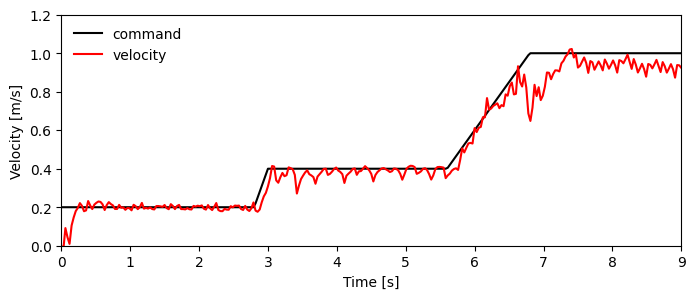

In [5]:
time = np.arange(len(data.record['velocity'])) / data.record_rate  # Seconds.
velocity = np.asarray(data.record['velocity'])

fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(time, data.record['command'], color='k', label='command')
ax.plot(time, velocity, color='r', label='velocity')
ax.set(xlabel='Time [s]', ylabel='Velocity [m/s]')
ax.legend(frameon=False)
ax.set_xlim(0, DURATION)
ax.set_ylim(0, 1.2)
plt.show()